# BÀI LAB 4: SO SÁNH ĐỘ TƯƠNG ĐỒNG ẢNH BẰNG WAVELET
## Phần 02: Tiền xử lý ảnh và Biến đổi Wavelet (TV3 - Văn Tôn)
- **Mục tiêu:** 
  1. Đọc ảnh, chuyển đổi không gian màu sang ảnh xám (Grayscale) và chuẩn hóa kích thước bằng `preprocessing.py`[cite: 46].
  2. Thực hiện biến đổi Wavelet rời rạc 2D (2D DWT) sử dụng thư viện `PyWavelets` với các họ `haar` và `db4`[cite: 46].
  3. Trực quan hóa các thành phần hệ số xấp xỉ (LL) và chi tiết (LH, HL, HH)[cite: 46].
  4. Khảo sát sự thay đổi của hệ số khi ảnh bị thay đổi hoặc có nhiễu[cite: 46].

### 1. Đọc ảnh, chuyển đổi không gian màu sang ảnh xám và chuẩn hóa kích thước
- Sử dụng module `preprocessing.py` để đọc ảnh, chuyển về ảnh xám (Grayscale) và chuẩn hóa kích thước $256 \times 256$ pixels.
- Sử dụng thư viện `PyWavelets` để thực hiện biến đổi Wavelet rời rạc 2D (2D DWT) với các họ `haar` và `db4`.

Đã chọn ra đúng 5 ảnh để thực hiện chạy thực nghiệm:
-> Đang xử lý: anh_dem.jpg


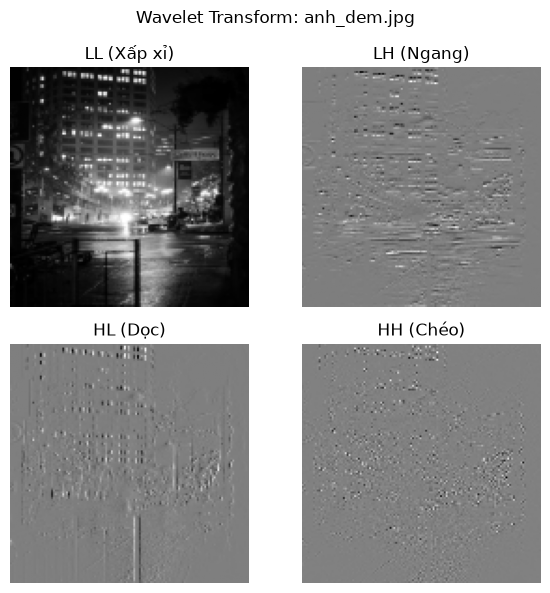

-> Đang xử lý: buom.jpg


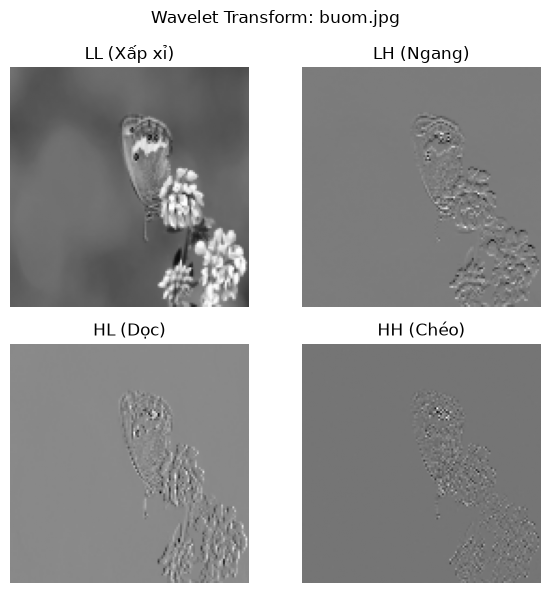

-> Đang xử lý: chim.jpg


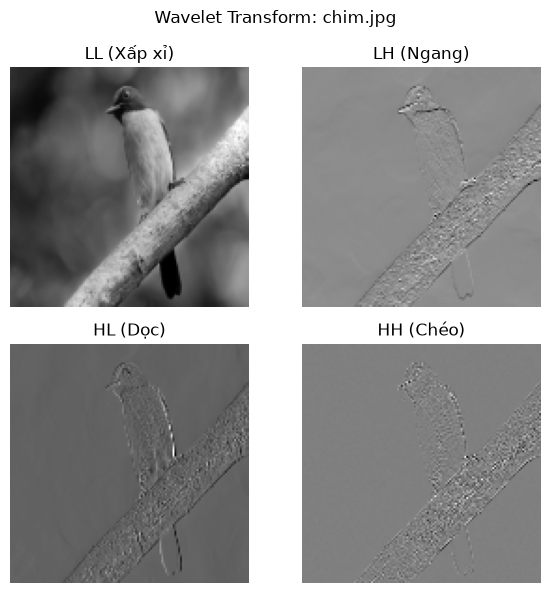

-> Đang xử lý: cong_trinh.jpg


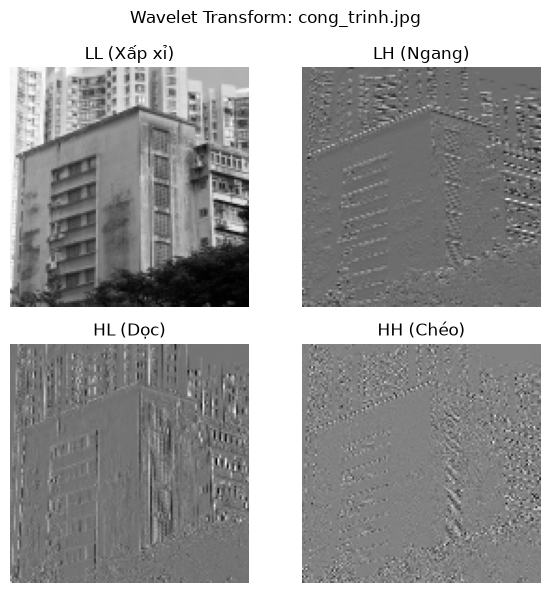

-> Đang xử lý: da_mat.jpg


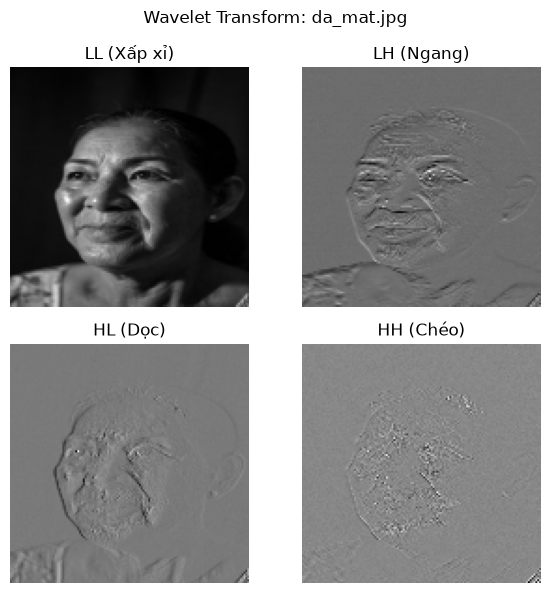

In [4]:
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pywt
import cv2

# Cấu hình đường dẫn
LAB4_DIR = Path.cwd().resolve().parent if Path.cwd().name == "notebook" else Path.cwd().resolve() / "lab_4"
SRC_DIR = LAB4_DIR / "src"
INPUT_DIR = LAB4_DIR / "data" / "input"
FIG_DIR = LAB4_DIR / "results" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from preprocessing import preprocess_image
from wavelet_transform import extract_first_level_components

# Lấy danh sách ảnh và giới hạn chỉ lấy đúng 5 ảnh đầu tiên
image_files = sorted([f for f in INPUT_DIR.glob("*.*") if f.suffix.lower() in [".png", ".jpg", ".jpeg", ".bmp", ".tif"]])[:5]

if not image_files:
    raise FileNotFoundError(f"Không tìm thấy file ảnh nào trong thư mục: {INPUT_DIR}")

print(f"Đã chọn ra đúng {len(image_files)} ảnh để thực hiện chạy thực nghiệm:")

# Duyệt qua từng ảnh trong danh sách 5 ảnh
for sample_path in image_files:
    print(f"-> Đang xử lý: {sample_path.name}")
    
    # 1. Tiền xử lý ảnh (Chuyển xám và resize về 256x256)
    img_gray = preprocess_image(sample_path, target_size=(256, 256))
    
    # 2. Trực quan hóa hệ số Wavelet (1 mức với 'haar')
    LL, LH, HL, HH = extract_first_level_components(img_gray, wavelet='haar')
    
    # Vẽ và lưu kết quả
    fig, axes = plt.subplots(2, 2, figsize=(6, 6))
    axes[0, 0].imshow(LL, cmap='gray'); axes[0, 0].set_title("LL (Xấp xỉ)")
    axes[0, 0].axis('off')
    axes[0, 1].imshow(LH, cmap='gray'); axes[0, 1].set_title("LH (Ngang)")
    axes[0, 1].axis('off')
    axes[1, 0].imshow(HL, cmap='gray'); axes[1, 0].set_title("HL (Dọc)")
    axes[1, 0].axis('off')
    axes[1, 1].imshow(HH, cmap='gray'); axes[1, 1].set_title("HH (Chéo)")
    axes[1, 1].axis('off')
    
    plt.suptitle(f"Wavelet Transform: {sample_path.name}")
    plt.tight_layout()
    
    # Lưu hình ảnh kết quả vào thư mục figures
    save_path = FIG_DIR / f"wavelet_{sample_path.stem}.png"
    plt.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()

###  Khảo sát sự thay đổi của hệ số khi ảnh bị thay đổi hoặc có nhiễu
- Thêm nhiễu Gauss vào ảnh gốc để quan sát sự biến động năng lượng tập trung ở các hệ số chi tiết cao (HH, HL, LH) so với hệ số xấp xỉ (LL).


[1/5] Đang khảo sát nhiễu cho ảnh: anh_dem.jpg


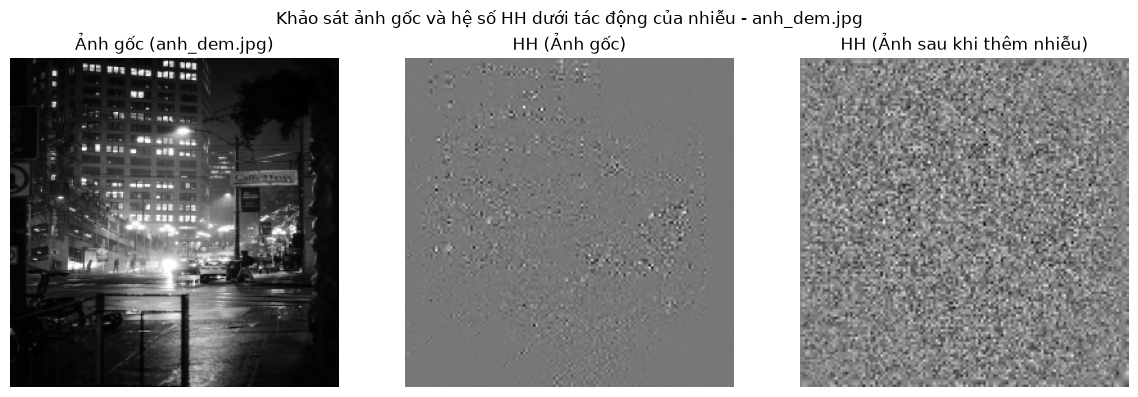


[2/5] Đang khảo sát nhiễu cho ảnh: buom.jpg


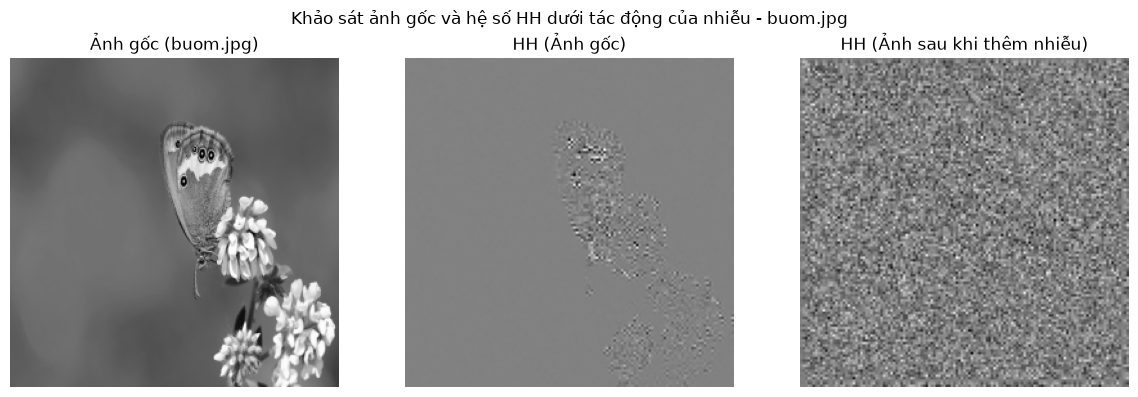


[3/5] Đang khảo sát nhiễu cho ảnh: chim.jpg


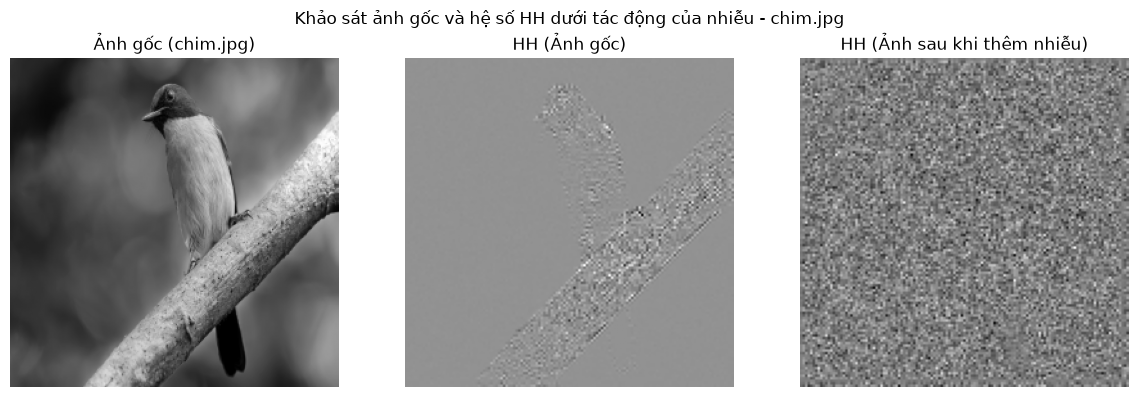


[4/5] Đang khảo sát nhiễu cho ảnh: cong_trinh.jpg


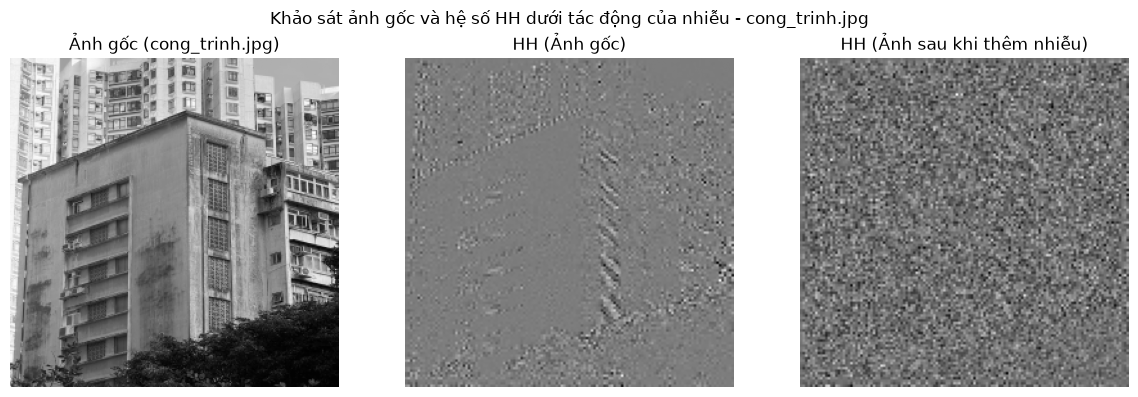


[5/5] Đang khảo sát nhiễu cho ảnh: da_mat.jpg


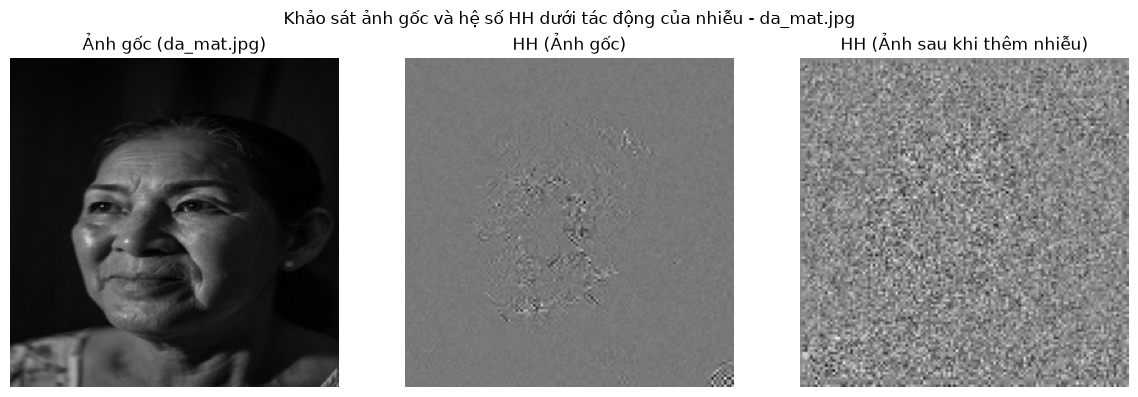


Nhận xét chung: Việc bố trí thêm ảnh gốc giúp quan sát trực quan sự tương quan giữa cấu trúc hình ảnh ban đầu và mức độ phân tán năng lượng tại dải hệ số chi tiết (HH) khi có nhiễu tác động.


In [5]:
# Khảo sát sự thay đổi hệ số khi toàn bộ 5 ảnh mẫu bị tác động bởi nhiễu Gauss (có hiển thị ảnh gốc để dễ so sánh)
for idx, sample_path in enumerate(image_files, 1):
    print(f"\n[{idx}/5] Đang khảo sát nhiễu cho ảnh: {sample_path.name}")
    
    # 1. Tiền xử lý ảnh (ảnh xám chuẩn hóa 256x256)
    img_gray = preprocess_image(sample_path, target_size=(256, 256))
    
    # 2. Thêm nhiễu Gauss vào ảnh
    noise = np.random.normal(0, 25, img_gray.shape)
    img_noisy = np.clip(img_gray.astype(np.float64) + noise, 0, 255).astype(np.uint8)
    
    # 3. Trích xuất hệ số wavelet với họ 'db4' cho cả ảnh gốc và ảnh nhiễu
    _, _, _, HH_orig = extract_first_level_components(img_gray, wavelet='db4')
    _, _, _, HH_noisy = extract_first_level_components(img_noisy, wavelet='db4')
    
    # 4. Trực quan hóa so sánh 3 cột: Ảnh gốc -> Hệ số HH gốc -> Hệ số HH ảnh nhiễu
    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    
    axes[0].imshow(img_gray, cmap='gray')
    axes[0].set_title(f"Ảnh gốc ({sample_path.name})")
    axes[0].axis('off')
    
    axes[1].imshow(HH_orig, cmap='gray')
    axes[1].set_title("HH (Ảnh gốc)")
    axes[1].axis('off')
    
    axes[2].imshow(HH_noisy, cmap='gray')
    axes[2].set_title("HH (Ảnh sau khi thêm nhiễu)")
    axes[2].axis('off')
    
    plt.suptitle(f"Khảo sát ảnh gốc và hệ số HH dưới tác động của nhiễu - {sample_path.name}")
    plt.tight_layout()
    
    # Lưu hình ảnh khảo sát nhiễu vào thư mục figures
    save_path = FIG_DIR / f"noise_analysis_with_original_{sample_path.stem}.png"
    plt.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()

print("\nNhận xét chung: Việc bố trí thêm ảnh gốc giúp quan sát trực quan sự tương quan giữa cấu trúc hình ảnh ban đầu và mức độ phân tán năng lượng tại dải hệ số chi tiết (HH) khi có nhiễu tác động.")

---
### **Kết luận và Tổng kết thực nghiệm (TV3 - Văn Tôn)**

1. **Về quá trình tiền xử lý ảnh (`preprocessing.py`):**
   * Đã xây dựng thành công hàm tự động đọc, chuyển đổi không gian màu sang ảnh xám (Grayscale) và chuẩn hóa kích thước cố định $256 \times 256$ pixels cho toàn bộ 5 ảnh mẫu. Việc đồng bộ này giúp loại bỏ sai lệch về kênh màu và đảm bảo tính đồng nhất cho ma trận dữ liệu đầu vào.

2. **Về phép biến đổi Wavelet rời rạc 2D (`wavelet_transform.py`):**
   * Đã ứng dụng thành công thư viện `PyWavelets` (`pywt`) với các họ wavelet phổ biến như `haar` và `db4` để phân rã hình ảnh thành các thành phần tần số khác nhau.
   * Trực quan hóa thành công dải xấp xỉ tổng thể (**LL**) và các dải chi tiết biên, góc (**LH, HL, HH**), qua đó làm rõ cấu trúc phân tầng năng lượng của hình ảnh.

3. **Về khảo sát tác động của nhiễu:**
   * Qua thực nghiệm thêm nhiễu Gauss vào 5 ảnh mẫu, kết quả biểu đồ so sánh cho thấy dải hệ số chi tiết chéo (**HH**) của ảnh gốc tập trung vào các biên cạnh sắc nét của đối tượng. 
   * Khi xuất hiện nhiễu, năng lượng phân bố tại dải **HH** thay đổi và phân tán rõ rệt. Điều này chứng minh rằng các hệ số wavelet tần số cao phản ánh rất nhạy bén với sự thay đổi của tín hiệu, tạo nền tảng vững chắc để chuyển sang bước lượng tử hóa và xây dựng mã Wavelet Hash ở phần tiếp theo của nhóm.